# Part 2 — baseline modeling and controlled experiments

Reproduces the phase prior and all 36 TF-IDF logistic-regression settings from the Python implementation. The winner is pooled criteria + phase, C=1, no year (historical validation log loss 0.5737533). Phase-specific F1 uses probability >=0.5; ROC-AUC/AP/log loss use success probabilities. IDs, reasons and reason embeddings are excluded from predictive inputs.

This notebook embeds the source implementation; it does not import project-specific Python modules. Standard-library and third-party imports are sufficient. Run cells in order from a fresh kernel. Default verification mode reads explicitly labeled historical references without fitting. Set `RUN_FULL=True` for fresh computation. All generated outputs are isolated under `deliverables/reproduced/`.


## Integrated deliverable provenance

Source: Michael’s origin/michael implementation. Model features, hyperparameters, splits and calibration procedure are unchanged. Part 1 references in preservation hashes are administrative only. For the authoritative cross-part error analysis use part2_error_analysis_final.ipynb. All new output paths below use deliverables/reproduced/.


## Imports, paths, execution mode and preservation checks


In [1]:
from pathlib import Path
import os
import hashlib
import json
# Configure numerical thread limits before NumPy/scikit-learn are imported.
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'part1-data').is_dir() and (p / 'part2-data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the repository or assembled midterm folder with both data directories.')
REPRO_ROOT = ROOT / 'deliverables/reproduced'
RUN_FULL = False  # Change to True for fresh complete training; verify mode never fits models.
# Original artifacts are read-only references. Every newly generated artifact stays below REPRO_ROOT.
def protected_hashes():
    paths = []
    for directory in ('part1-data', 'part2-data', 'outputs', 'part1-results', 'part2-results',
                      'part2/outputs', 'part2/calibration_outputs', 'writeup'):
        if (ROOT / directory).exists():
            paths.extend(p for p in (ROOT / directory).rglob('*') if p.is_file())
    paths.extend(ROOT.glob('*.py'))
    paths.extend((ROOT / 'part2').glob('*.py'))
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
ORIGINAL_HASHES = protected_hashes()
print('Mode:', 'full fresh reproduction' if RUN_FULL else 'verification only — no model fitting')


Mode: verification only — no model fitting


In [2]:
DATA = ROOT / 'part2-data'
OUTPUT = REPRO_ROOT / 'part2_modeling'
REFERENCE_OUTPUT = ROOT / 'part2' / 'outputs'
REFERENCE_CALIBRATION = ROOT / 'part2' / 'calibration_outputs'
SEED = 5785
PHASES = ('I', 'II', 'III')
TEXT_SETS = {
    'clinical': ('diseases_cleaned', 'drugs', 'icdcodes'),
    'criteria': ('criteria',),
    'all_text': ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes'),
}
CS = (0.1, 1.0, 10.0)
THRESHOLD = 0.5
OUTPUT.mkdir(parents=True, exist_ok=True)


In [3]:
import ast
import re
import pandas as pd


In [4]:
TEXT_COLUMNS = ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes')


### `load_data`

Implementation copied from `part2/data.py`.


In [5]:
def load_data():
    names = ('outcome_train', 'outcome_val', 'outcome_test', 'part2_sample_submission')
    missing = [str(DATA / f'{n}.csv') for n in names if not (DATA / f'{n}.csv').exists()]
    if missing:
        raise FileNotFoundError(f'Missing files: {missing}')
    train, val, test, sample = [pd.read_csv(DATA / f'{n}.csv') for n in names]
    for frame, expected in zip((train, val, test), (8037, 1013, 1500)):
        assert len(frame) == expected
        assert frame.ID.is_unique and frame.ID.notna().all()
        assert frame.trial_id.notna().all()
        assert set(frame.phase) == set(PHASES)
        assert not frame.duplicated(['trial_id', 'phase']).any()
        assert frame.ID.eq(frame.trial_id + '_' + frame.phase).all()
        assert set(TEXT_COLUMNS + ('start_year',)).issubset(frame.columns)
    for frame in (train, val):
        assert set(frame.label) == {0, 1}
        assert frame.groupby('trial_id').label.nunique().max() == 1
    for a, b in ((train, val), (train, test), (val, test)):
        assert not set(a.trial_id).intersection(b.trial_id), 'Cross-split trial leakage'
    assert sample.ID.equals(test.ID)
    assert list(sample.columns) == ['ID', 'label']
    return train, val, test, sample


### `flatten`

Implementation copied from `part2/data.py`.


In [6]:
def flatten(value):
    """Decode nested Python-list strings safely (including nested ICD lists)."""
    if isinstance(value, (list, tuple)):
        return ' '.join(flatten(v) for v in value)
    if pd.isna(value):
        return ''
    value = str(value).strip()
    if value.startswith('['):
        try:
            return flatten(ast.literal_eval(value))
        except (ValueError, SyntaxError):
            pass
    return re.sub(r'\s+', ' ', value).strip()


### `prepare`

Implementation copied from `part2/data.py`.


In [7]:
def prepare(frame):
    # Explicit allowlist: IDs, labels, reason labels/embeddings never enter features.
    result = frame[list(TEXT_COLUMNS) + ['phase', 'start_year']].copy()
    for col in TEXT_COLUMNS:
        result[col] = result[col].map(flatten)
    return result


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


### `build_features`

Implementation copied from `part2/features.py`.


In [9]:
def build_features(text_columns, use_year, pooled):
    transformers = []
    for col in text_columns:
        transformers.append((col, TfidfVectorizer(
            lowercase=True, strip_accents='unicode', ngram_range=(1, 2),
            min_df=3, max_df=1.0, sublinear_tf=True,
            # Preserve decimal ICD codes as tokens, including one-character words.
            token_pattern=r'(?u)\b\w[\w.]*\b',
            max_features=15000 if col == 'criteria' else 5000), col))
    if pooled:
        transformers.append(('phase', OneHotEncoder(handle_unknown='ignore'), ['phase']))
    if use_year:
        transformers.append(('year', Pipeline([
            ('impute', SimpleImputer(strategy='median', add_indicator=True)),
            ('scale', StandardScaler()),
        ]), ['start_year']))
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0)


In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression


### `fit_features`

Implementation copied from `part2/training.py`.


In [11]:
def fit_features(train, val, text_columns, use_year, regime):
    groups = ('pooled',) if regime == 'pooled' else PHASES
    prepared = {}
    for group in groups:
        tm = np.ones(len(train), dtype=bool) if group == 'pooled' else train.phase.eq(group).to_numpy()
        vm = np.ones(len(val), dtype=bool) if group == 'pooled' else val.phase.eq(group).to_numpy()
        features = build_features(text_columns, use_year, regime == 'pooled')
        xt = features.fit_transform(train.loc[tm])
        xv = features.transform(val.loc[vm])
        prepared[group] = (features, xt, xv, tm, vm)
    return prepared


### `fit_classifiers`

Implementation copied from `part2/training.py`.


In [12]:
def fit_classifiers(prepared, labels, c):
    train_p = np.empty(len(labels))
    val_p = np.empty(sum(int(v[4].sum()) for v in prepared.values()))
    models = {}
    for group, (features, xt, xv, tm, vm) in prepared.items():
        model = LogisticRegression(C=c, solver='liblinear', max_iter=2000, tol=1e-5, random_state=SEED)
        model.fit(xt, labels[tm])
        if model.n_iter_.max() >= model.max_iter:
            raise RuntimeError(f'Nonconvergence for {group}, C={c}')
        train_p[tm] = model.predict_proba(xt)[:, 1]
        val_p[vm] = model.predict_proba(xv)[:, 1]
        models[group] = dict(features=features, classifier=model)
    return models, train_p, val_p


### `predict`

Implementation copied from `part2/training.py`.


In [13]:
def predict(bundle, frame):
    if bundle['kind'] == 'prior':
        return frame.phase.map(bundle['priors']).to_numpy(dtype=float)
    p = np.empty(len(frame))
    for group, components in bundle['models'].items():
        mask = np.ones(len(frame), dtype=bool) if group == 'pooled' else frame.phase.eq(group).to_numpy()
        if mask.any():
            x = components['features'].transform(frame.loc[mask])
            p[mask] = components['classifier'].predict_proba(x)[:, 1]
    return p


In [14]:
import numpy as np
from sklearn.metrics import log_loss, f1_score, roc_auc_score, average_precision_score


### `evaluate`

Implementation copied from `part2/evaluation.py`.


In [15]:
def evaluate(frame, probabilities):
    p = np.asarray(probabilities, dtype=float)
    if p.shape != (len(frame),) or not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Expected one finite probability per row in [0, 1]')
    result = {}
    for phase in ('overall', *PHASES):
        mask = np.ones(len(frame), dtype=bool) if phase == 'overall' else frame.phase.eq(phase).to_numpy()
        y, pred = frame.label.to_numpy()[mask], p[mask]
        result[f'{phase}_n'] = len(y)
        if not len(y):
            for metric in ('log_loss', 'f1', 'roc_auc', 'average_precision'):
                result[f'{phase}_{metric}'] = np.nan
            continue
        result[f'{phase}_log_loss'] = log_loss(y, pred, labels=[0, 1])
        result[f'{phase}_f1'] = f1_score(y, pred >= THRESHOLD, zero_division=0)
        both = len(np.unique(y)) == 2
        result[f'{phase}_roc_auc'] = roc_auc_score(y, pred) if both else np.nan
        result[f'{phase}_average_precision'] = average_precision_score(y, pred) if both else np.nan
    result['phase_macro_log_loss'] = np.mean([result[f'{p}_log_loss'] for p in PHASES])
    return result


In [16]:
import pickle
import numpy as np
import pandas as pd


### `validate_submission`

Implementation copied from `part2/submission.py`.


In [17]:
def validate_submission(submission, test, sample):
    assert list(submission.columns) == ['ID', 'label']
    assert len(submission) == len(test) == 1500
    assert submission.ID.equals(test.ID) and submission.ID.equals(sample.ID)
    assert submission.ID.is_unique and not submission.isna().any().any()
    assert np.isfinite(submission.label).all() and submission.label.between(0, 1).all()


### `generate`

Implementation copied from `part2/submission.py`.


In [18]:
def generate(bundle, test, sample):
    submission = pd.DataFrame({'ID': test.ID, 'label': predict(bundle, prepare(test))})
    validate_submission(submission, test, sample)
    path = OUTPUT / 'part2_submission.csv'
    submission.to_csv(path, index=False)
    validate_submission(pd.read_csv(path), test, sample)
    return path


In [19]:
import json
from itertools import combinations
import pandas as pd


### `audit`

Implementation copied from `part2/audit.py`.


In [20]:
def audit(frames):
    OUTPUT.mkdir(parents=True, exist_ok=True)
    schemas, missing, balance, years, duplicates = [], [], [], [], []
    for split, frame in frames.items():
        for col in frame:
            schemas.append(dict(split=split, rows=len(frame), column=col, dtype=str(frame[col].dtype)))
            missing.append(dict(split=split, column=col, missing=int(frame[col].isna().sum())))
        clean = prepare(frame)
        for col in TEXT_COLUMNS:
            missing.append(dict(split=split, column=col + '_empty_after_parsing', missing=int(clean[col].eq('').sum())))
        for phase, group in [('overall', frame), *list(frame.groupby('phase'))]:
            balance.append(dict(split=split, phase=phase, rows=len(group), unique_trials=group.trial_id.nunique(),
                                successes=int(group.label.sum()) if 'label' in group else None,
                                success_rate=float(group.label.mean()) if 'label' in group else None))
        for year, n in frame.start_year.value_counts(dropna=False).sort_index().items():
            years.append(dict(split=split, start_year=year, rows=n))
        duplicates.append(dict(split=split, exact_duplicate_rows=int(frame.duplicated().sum()),
            duplicate_trial_phase=int(frame.duplicated(['trial_id', 'phase']).sum()),
            multi_phase_trials=int((frame.groupby('trial_id').phase.nunique() > 1).sum()),
            extra_phase_rows=len(frame)-frame.trial_id.nunique(),
            year_min=frame.start_year.min(), year_median=frame.start_year.median(), year_max=frame.start_year.max()))
    overlap = []
    # Exact text matches may indicate related protocols; report separately from ID leakage.
    for (a, fa), (b, fb) in combinations(frames.items(), 2):
        ca, cb = prepare(fa), prepare(fb)
        for cols in [('trial_id',), ('criteria',), TEXT_COLUMNS]:
            aa, bb = (fa, fb) if cols == ('trial_id',) else (ca, cb)
            ha = pd.util.hash_pandas_object(aa[list(cols)], index=False)
            hb = pd.util.hash_pandas_object(bb[list(cols)], index=False)
            if cols == ('criteria',):
                ha, hb = ha[aa.criteria.ne('')], hb[bb.criteria.ne('')]
            overlap.append(dict(split_a=a, split_b=b, key='+'.join(cols), shared_keys=len(set(ha) & set(hb))))
    tables = dict(schema=schemas, missing_values=missing, class_balance=balance, start_year_counts=years,
                  duplicates_and_years=duplicates, cross_split_overlap=overlap)
    for name, rows in tables.items():
        pd.DataFrame(rows).to_csv(OUTPUT / f'{name}.csv', index=False)
    report = ['# Initial data audit', '', 'Text: criteria, diseases_cleaned, drugs, icdcodes. Additional available text/categorical fields: phase_detail, matched_drugs, drug_targets, drug_actions, drug_pathways, drug_smiles. Phase is categorical; start_year is numerical. ID and trial_id are matching keys, label is the binary target. Optional pathway_catalog has 2,501 rows and five columns; it is unused.', '', 'All splits have no duplicate rows or duplicate trial-phase records. Multiple phase rows of the same trial are retained within splits; no trial crosses splits. Cross-split exact text matches are reported as a possible related-protocol leakage risk. Year counts include missing values. Class balance and success rates are row-weighted, consistent with the assignment metric.', '']
    for name, rows in tables.items():
        report.extend([f'## {name}', '', '```text', pd.DataFrame(rows).to_string(index=False), '```', ''])
    (OUTPUT / 'data_audit.md').write_text('\n'.join(report))
    print('CLASS BALANCE\n' + pd.DataFrame(balance).to_string(index=False))
    print('DUPLICATES / YEARS\n' + pd.DataFrame(duplicates).to_string(index=False))
    print('OVERLAP\n' + pd.DataFrame(overlap).to_string(index=False))
    print('MISSING VALUES\n' + pd.DataFrame(missing).query('missing > 0').to_string(index=False))
    (OUTPUT / 'audit_summary.json').write_text(json.dumps(tables, indent=2, default=str))


## Audit actual input data before fitting


In [21]:
train, val, test, sample = load_data()
audit(dict(train=train, val=val, test=test))


CLASS BALANCE
split   phase  rows  unique_trials  successes  success_rate
train overall  8037           7535     4466.0      0.555680
train       I  1012           1012      573.0      0.566206
train      II  3950           3950     1884.0      0.476962
train     III  3075           3075     2009.0      0.653333
  val overall  1013            901      561.0      0.553801
  val       I   149            149       85.0      0.570470
  val      II   501            501      236.0      0.471058
  val     III   363            363      240.0      0.661157
 test overall  1500           1442        NaN           NaN
 test       I   500            500        NaN           NaN
 test      II   500            500        NaN           NaN
 test     III   500            500        NaN           NaN
DUPLICATES / YEARS
split  exact_duplicate_rows  duplicate_trial_phase  multi_phase_trials  extra_phase_rows  year_min  year_median  year_max
train                     0                      0               

## Original controlled experiment implementation

Each field has train-fitted TF-IDF; pooled models add one-hot phase. Year models use train-median imputation and scaling. Phase-specific models fit independent preprocessing. The grid and solver settings are unchanged. Validation selects the winner; it never fits model coefficients or preprocessing.


In [22]:
import hashlib
import json
import pickle
import platform
import time
from itertools import product
import numpy as np
import pandas as pd
import scipy
import sklearn


### `main`

Implementation copied from `part2/experiments.py`.


In [23]:
def run_modeling_experiments():
    train, val, test, sample = load_data()
    audit(dict(train=train, val=val, test=test))
    xt, xv = prepare(train), prepare(val)
    records, predictions = [], []
    best_loss, best_id = float('inf'), None

    def record(config, bundle, pt, pv, seconds):
        nonlocal best_loss, best_id
        row = {**config, 'threshold': THRESHOLD, 'fit_seconds': seconds}
        row.update({f'train_{k}': v for k, v in evaluate(train, pt).items()})
        row.update({f'val_{k}': v for k, v in evaluate(val, pv).items()})
        records.append(row)
        pred = val[['ID', 'trial_id', 'phase', 'label']].copy()
        pred['experiment'] = config['experiment']
        pred['probability'] = pv
        predictions.append(pred)
        loss = row['val_overall_log_loss']
        print(f"{config['experiment']:35s} train={row['train_overall_log_loss']:.5f} val={loss:.5f}", flush=True)
        if loss < best_loss:
            best_loss, best_id = loss, config['experiment']
            bundle['config'] = config
            with (OUTPUT / 'best_model.pkl').open('wb') as f:
                pickle.dump(bundle, f)
        pd.DataFrame(records).to_csv(OUTPUT / 'experiment_results.csv', index=False)

    prior = dict(kind='prior', priors=train.groupby('phase').label.mean().to_dict())
    record(dict(experiment='phase_prior', kind='prior', text_set='none', use_year=False, regime='phase_specific', C=None),
           prior, predict(prior, xt), predict(prior, xv), 0.0)
    for text_set, use_year, regime in product(TEXT_SETS, (False, True), ('pooled', 'phase_specific')):
        start = time.perf_counter()
        prepared = fit_features(xt, xv, TEXT_SETS[text_set], use_year, regime)
        feature_seconds = time.perf_counter() - start
        for c in CS:
            start = time.perf_counter()
            models, pt, pv = fit_classifiers(prepared, train.label.to_numpy(), c)
            config = dict(experiment=f'{text_set}_year{int(use_year)}_{regime}_C{c:g}', kind='logistic',
                          text_set=text_set, use_year=use_year, regime=regime, C=c)
            record(config, dict(kind='logistic', models=models), pt, pv,
                   feature_seconds + time.perf_counter() - start)
    pd.concat(predictions, ignore_index=True).to_csv(OUTPUT / 'validation_predictions.csv', index=False)
    with (OUTPUT / 'best_model.pkl').open('rb') as f:
        best = pickle.load(f)
    pv = predict(best, xv)
    assert np.allclose(evaluate(val, pv)['overall_log_loss'], best_loss)
    selected = val[['ID', 'trial_id', 'phase', 'label']].copy()
    selected['probability'] = pv
    selected['predicted_label'] = (pv >= THRESHOLD).astype(int)
    selected.to_csv(OUTPUT / 'best_validation_predictions.csv', index=False)
    path = generate(best, test, sample)
    metadata = dict(seed=SEED, best_experiment=best_id, validation_log_loss=best_loss,
        selection='minimum overall validation log loss; no validation refit',
        threshold=THRESHOLD, python=platform.python_version(), pandas=pd.__version__,
        numpy=np.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__,
        inputs_sha256={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(DATA.glob('*.csv'))},
        feature_settings=dict(min_df=3, ngram_range=[1, 2], sublinear_tf=True,
                              criteria_max_features=15000, other_max_features=5000),
        logistic_settings=dict(solver='liblinear', max_iter=2000, tol=1e-5),
        submission=str(path))
    (OUTPUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2))
    table = pd.DataFrame(records).sort_values('val_overall_log_loss')
    print(table[['experiment', 'train_overall_log_loss', 'val_overall_log_loss', 'val_phase_macro_log_loss']].to_string(index=False))
    print(f'BEST: {best_id}; submission: {path}')


In [24]:
if RUN_FULL:
    run_modeling_experiments()
else:
    print('Skipped the 37-model experiment suite in verification mode.')


Skipped the 37-model experiment suite in verification mode.


In [25]:
import json
import pandas as pd


### `markdown_table`

Implementation copied from `part2/report.py`.


In [26]:
def markdown_table(frame):
    def fmt(v):
        return f'{v:.5f}' if isinstance(v, float) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, frame.columns)) + ' |',
                      '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |',
                      *['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in frame.itertuples(index=False, name=None)]])


### `main`

Implementation copied from `part2/report.py`.


In [27]:
def write_modeling_report():
    results = pd.read_csv(OUTPUT / 'experiment_results.csv')
    metadata = json.loads((OUTPUT / 'run_metadata.json').read_text())
    best = results.loc[results.experiment.eq(metadata['best_experiment'])].iloc[0]
    lines = ['# Part 2 baseline experiment report', '',
        'Selection uses minimum overall validation binary log loss. All fits use only outcome_train; '
        'validation is used for evaluation and model selection, never fitting preprocessing or refitting the winner. '
        'F1 uses probability >= 0.5, with label=1 positive. PR-AUC means average precision, not trapezoidal area. '
        'Phase-macro log loss is also provided because the test set has equal phase sizes.', '',
        f"Selected: **{metadata['best_experiment']}**, log loss **{best.val_overall_log_loss:.5f}**. "
        f"The phase prior scores {results.iloc[0].val_overall_log_loss:.5f}.", '',
        '## All completed experiments', '',
        'clinical = diseases_cleaned + drugs + icdcodes; criteria = eligibility criteria; all_text = all four. '
        'Each text field has its own TF-IDF vocabulary and normalization. Pooled models include one-hot phase; '
        'phase-specific models fit independent vocabularies, year transformations, and classifiers. '
        'The same C is used for all three independent phase models. No class weighting or threshold tuning.', '']
    cols = ['experiment', 'train_overall_log_loss', 'val_overall_log_loss', 'val_phase_macro_log_loss',
            *[f'val_{p}_log_loss' for p in PHASES]]
    lines += [markdown_table(results[cols]), '']
    for phase in PHASES:
        lines += [f'## Phase {phase} validation metrics', '', markdown_table(results[
            ['experiment', f'val_{phase}_n', f'val_{phase}_log_loss', f'val_{phase}_f1',
             f'val_{phase}_roc_auc', f'val_{phase}_average_precision']]), '']
    lines += ['## Interpretation and limits', '',
        'The pooled criteria-only C=1 model wins this grid. Adding disease/drug/ICD text does not beat it; '
        'those fields may add sparse trial-specific associations that do not generalize. '
        'Larger C consistently widens the train/validation gap. Year does not improve the winning configuration. '
        'Pooled models generally benefit from sharing text coefficients across phases, especially with only 1,012 Phase I training rows. '
        'These are validation observations, not evidence of test performance.', '',
        'The random-by-trial validation split is earlier than the test distribution: train years 1993–2013, '
        'validation 1995–2013, test 2014–2021 (nonmissing). There are 21/6/0 missing years. '
        'A future trial-grouped temporal holdout drawn from training would be useful before more complex models. '
        'Repeated model selection on 1,013 validation rows can be optimistic; Phase I has only 149 rows. '
        'Combined-phase trials are correlated across phase rows, so row metrics are not independent-trial uncertainty estimates.', '',
        'There are no shared trial IDs or duplicate trial-phase rows. Training/validation share seven exact nonempty '
        'normalized eligibility texts and one full four-field text signature across distinct IDs; related protocols may '
        'make validation optimistic. Test has no such exact matches. The provided split is retained. '
        'No identifiers, phase_detail, reason labels, embeddings, drug-knowledge fields, or external data are predictive inputs.', '',
        'Reason-category error analysis and the assignment’s subsequent classifier improvement are intentionally deferred '
        'until review of these baselines. See ../ERROR_ANALYSIS.md. The assignment also requests notebook-format source; '
        '../baseline_workflow.ipynb runs this modular workflow, but a final report and completed analysis remain to be assembled.', '',
        '## Reproducibility', '',
        'run_metadata.json records input SHA-256 hashes, library versions, seed, vectorizer and solver settings. '
        'experiment_results.csv contains all configuration choices and train/validation metrics, including overall metrics. '
        'validation_predictions.csv preserves every experiment’s validation probabilities; best_validation_predictions.csv '
        'supports the later error analysis. best_model.pkl is a trusted local pickle; use the recorded environment to reload it. '
        'Fit times include feature fitting for each configuration even though features are reused across C values.', '']
    (OUTPUT / 'experiment_report.md').write_text('\n'.join(lines))
    print(markdown_table(results[['experiment', 'val_overall_log_loss']]))


In [28]:
reference_path = REFERENCE_OUTPUT / 'experiment_results.csv'
reference = pd.read_csv(reference_path if reference_path.exists() else OUTPUT / 'experiment_results.csv')
assert len(reference) == 37
best = reference.loc[reference.val_overall_log_loss.idxmin()]
assert best.experiment == 'criteria_year0_pooled_C1'
assert abs(best.val_overall_log_loss - 0.5737533226117716) < 1e-12
if RUN_FULL:
    fresh = pd.read_csv(OUTPUT / 'experiment_results.csv')
    left = fresh.set_index('experiment').sort_index()
    right = reference.set_index('experiment').sort_index()
    metric_cols = [col for col in right if col.startswith(('train_', 'val_'))]
    assert np.allclose(left[metric_cols], right[metric_cols], atol=1e-6)
    write_modeling_report()
    shown = fresh
else:
    print('Displaying historical reference results; not freshly trained.')
    shown = reference
display(shown[['experiment','train_overall_log_loss','val_overall_log_loss','val_phase_macro_log_loss']].sort_values('val_overall_log_loss'))
original_submission_path = REFERENCE_OUTPUT / 'part2_submission.csv'
original_submission = pd.read_csv(original_submission_path if original_submission_path.exists() else OUTPUT / 'part2_submission.csv')
validate_submission(original_submission, test, sample)
if RUN_FULL:
    reproduced_submission = pd.read_csv(OUTPUT / 'part2_submission.csv')
    validate_submission(reproduced_submission, test, sample)
    assert np.allclose(reproduced_submission.label, original_submission.label, atol=1e-6)


Displaying historical reference results; not freshly trained.


,experiment,train_overall_log_loss,val_overall_log_loss,val_phase_macro_log_loss
14,criteria_year0_pooled_C1,0.469032,0.573753,0.568160
20,criteria_year1_pooled_C1,0.468632,0.574845,0.568966
25,all_text_year0_pooled_C0.1,0.542386,0.586351,0.587209
17,criteria_year0_phase_specific_C1,0.468228,0.587201,0.585756
26,all_text_year0_pooled_C1,0.367626,0.587678,0.590110
23,criteria_year1_phase_specific_C1,0.466957,0.588498,0.586752
31,all_text_year1_pooled_C0.1,0.541201,0.588580,0.588685
32,all_text_year1_pooled_C1,0.367486,0.589479,0.591577
29,all_text_year0_phase_specific_C1,0.368576,0.592983,0.590094
35,all_text_year1_phase_specific_C1,0.367976,0.595749,0.592361


## Train/validation performance comparison


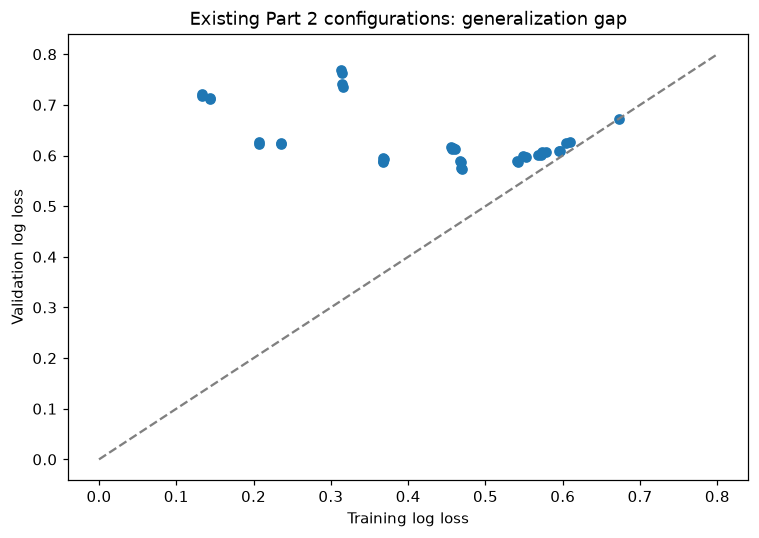

In [29]:
import matplotlib.pyplot as plt
plot_rows = shown.sort_values('val_overall_log_loss')
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(plot_rows.train_overall_log_loss, plot_rows.val_overall_log_loss)
ax.plot([0, .8], [0, .8], linestyle='--', color='gray')
ax.set(xlabel='Training log loss', ylabel='Validation log loss', title='Existing Part 2 configurations: generalization gap')
fig.tight_layout()
fig.savefig(OUTPUT / 'train_validation_log_loss.png', dpi=140)
plt.show()


## Findings

The historical winner has row-weighted validation log loss 0.57375; stronger regularization controls overfitting. Overall loss weights phases by validation sample count; phase-macro loss weights all three equally, matching the equal phase counts in test. The later test cohort can shift calibration. No Kaggle score is inferred from validation.


In [30]:
after = protected_hashes()
assert all(after.get(path) == digest for path, digest in ORIGINAL_HASHES.items())
print('Existing source files, data, models, reports, predictions and submissions are unchanged.')


Existing source files, data, models, reports, predictions and submissions are unchanged.
